<a href="https://colab.research.google.com/github/sagarsagat5360-svg/Data-Type-Memory-Performance-Benchmark-Lab/blob/main/numpy_dtype_benchmark_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NumPy Data Type Memory & Performance Benchmark Lab

**Goal:** Measure how dtype choice (int8 to int64, float16 to float64) changes memory usage, speed and precision on 1-million-element arrays.

**NumPy topics:** `dtype`, `astype()`, `itemsize` / `nbytes`, `np.arange`, `np.random`, `np.ones`, overflow behaviour, performance timing

**Steps**
1. Create the same 1M-element array in 7 dtypes
2. Record size, itemsize and nbytes in a table
3. Time `sum` and `multiply` for each dtype
4. Demonstrate overflow and float precision loss
5. Plot memory vs time and write recommendations

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import timeit

print("NumPy version:", np.__version__)

NumPy version: 2.1.3


## Step 1: Create the same 1M-element array in every dtype
Values are random integers from 0 to 99, so they fit safely in every dtype (int8 max is 127). That way each array holds identical data and only the dtype changes.

In [2]:
N = 1_000_000
rng = np.random.default_rng(42)
base = rng.integers(0, 100, size=N)          # int64 source data

dtypes = [np.int8, np.int16, np.int32, np.int64,
          np.float16, np.float32, np.float64]

arrays = {np.dtype(dt).name: base.astype(dt) for dt in dtypes}

for name, arr in arrays.items():
    print(f"{name:8s} -> shape={arr.shape}, first 5 values={arr[:5]}")

int8     -> shape=(1000000,), first 5 values=[ 8 77 65 43 43]
int16    -> shape=(1000000,), first 5 values=[ 8 77 65 43 43]
int32    -> shape=(1000000,), first 5 values=[ 8 77 65 43 43]
int64    -> shape=(1000000,), first 5 values=[ 8 77 65 43 43]
float16  -> shape=(1000000,), first 5 values=[ 8. 77. 65. 43. 43.]
float32  -> shape=(1000000,), first 5 values=[ 8. 77. 65. 43. 43.]
float64  -> shape=(1000000,), first 5 values=[ 8. 77. 65. 43. 43.]


## Step 2: Record size, itemsize and nbytes

In [3]:
rows = []
for name, arr in arrays.items():
    rows.append({
        "dtype": name,
        "size (elements)": arr.size,
        "itemsize (bytes)": arr.itemsize,
        "nbytes": arr.nbytes,
        "memory (MB)": round(arr.nbytes / 1024**2, 3),
    })

mem_df = pd.DataFrame(rows).set_index("dtype")
mem_df["vs int64 (x smaller)"] = (mem_df.loc["int64", "nbytes"] / mem_df["nbytes"]).round(1)
mem_df

,size (elements),itemsize (bytes),nbytes,memory (MB),vs int64 (x smaller)
dtype,,,,,
int8,1000000,1,1000000,0.954,8.0
int16,1000000,2,2000000,1.907,4.0
int32,1000000,4,4000000,3.815,2.0
int64,1000000,8,8000000,7.629,1.0
float16,1000000,2,2000000,1.907,4.0
float32,1000000,4,4000000,3.815,2.0
float64,1000000,8,8000000,7.629,1.0


## Step 3: Time `sum` and `multiply` for each dtype
We use `timeit.repeat` and take the **minimum** of several runs, which is the most reliable estimate because it is least affected by other processes on the machine.

In [4]:
def best_time(func, number=50, repeat=5):
    # average seconds per call, using the best of `repeat` runs
    return min(timeit.repeat(func, number=number, repeat=repeat)) / number

results = []
for name, arr in arrays.items():
    t_sum = best_time(lambda a=arr: a.sum())
    t_mul = best_time(lambda a=arr: a * 2)
    results.append({"dtype": name,
                    "sum (ms)": t_sum * 1000,
                    "multiply (ms)": t_mul * 1000})

time_df = pd.DataFrame(results).set_index("dtype").round(4)
time_df

/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:53: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


,sum (ms),multiply (ms)
dtype,,
int8,0.7112,0.0890
int16,0.7166,0.1817
int32,0.9726,0.5365
int64,0.5011,1.1698
float16,4.5250,19.4730
float32,0.2950,0.3564
float64,0.3621,0.8827


> **Note on `sum`:** for integer arrays, `arr.sum()` accumulates in a wider type (platform int, usually int64) to avoid overflow, so the result is correct even for int8. Float16 has no such protection, which the next cell shows.

In [5]:
print("Result of sum() for each dtype (true sum:", base.sum(), ")")
for name, arr in arrays.items():
    s = arr.sum()
    print(f"{name:8s} -> sum = {s}   (result dtype: {np.asarray(s).dtype})")

Result of sum() for each dtype (true sum: 49468897 )
int8     -> sum = 49468897   (result dtype: int64)
int16    -> sum = 49468897   (result dtype: int64)
int32    -> sum = 49468897   (result dtype: int64)
int64    -> sum = 49468897   (result dtype: int64)
float16  -> sum = inf   (result dtype: float16)
float32  -> sum = 49468900.0   (result dtype: float32)
float64  -> sum = 49468897.0   (result dtype: float64)


/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:53: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


## Step 4a: Integer overflow
When a value does not fit in the dtype, NumPy arrays silently **wrap around**. That is fast, but dangerous.

In [6]:
# (a) Casting a too-large value down to int8
big = np.array([200], dtype=np.int64)
print("200 as int8        :", big.astype(np.int8))        # wraps to -56

# (b) Arithmetic overflow inside an int8 array
a = np.array([100, 120, 127], dtype=np.int8)
print("int8  + 10         :", a + np.int8(10))            # wraps to negatives

# (c) Same arithmetic in a wider dtype is correct
print("int16 + 10         :", a.astype(np.int16) + 10)

# (d) Safe limits of every integer type
for dt in (np.int8, np.int16, np.int32, np.int64):
    info = np.iinfo(dt)
    print(f"{np.dtype(dt).name:6s} range: {info.min} to {info.max}")

200 as int8        : [-56]
int8  + 10         : [ 110 -126 -119]
int16 + 10         : [110 130 137]
int8   range: -128 to 127
int16  range: -32768 to 32767
int32  range: -2147483648 to 2147483647
int64  range: -9223372036854775808 to 9223372036854775807


## Step 4b: Float precision loss

In [7]:
# (a) The same number stored at different precisions
x = 0.1
for dt in (np.float16, np.float32, np.float64):
    print(f"{np.dtype(dt).name:8s}: {float(dt(x)):.20f}")

# (b) Large integers cannot be represented exactly in small floats
print()
print("float16(2049)      :", np.float16(2049))           # rounds to 2048
print("float32(16777217)  :", np.float32(16777217))       # rounds to 16777216
print("float64(16777217)  :", np.float64(16777217))       # exact

# (c) float16 overflow to inf (max value is 65504)
print()
print("float16 max        :", np.finfo(np.float16).max)
print("float16 sum of 1M  :", arrays['float16'].sum(), "   <- overflowed to inf")
print("float64 sum of 1M  :", arrays['float64'].sum())

# (d) Machine precision (epsilon) of each float type
print()
for dt in (np.float16, np.float32, np.float64):
    print(f"{np.dtype(dt).name:8s} eps = {np.finfo(dt).eps}")

float16 : 0.09997558593750000000
float32 : 0.10000000149011611938
float64 : 0.10000000000000000555

float16(2049)      : 2048.0
float32(16777217)  : 16777216.0
float64(16777217)  : 16777217.0

float16 max        : 65500.0
float16 sum of 1M  : inf    <- overflowed to inf
float64 sum of 1M  : 49468897.0

float16  eps = 0.0009765625
float32  eps = 1.1920928955078125e-07
float64  eps = 2.220446049250313e-16


## Step 5: Plot memory vs time

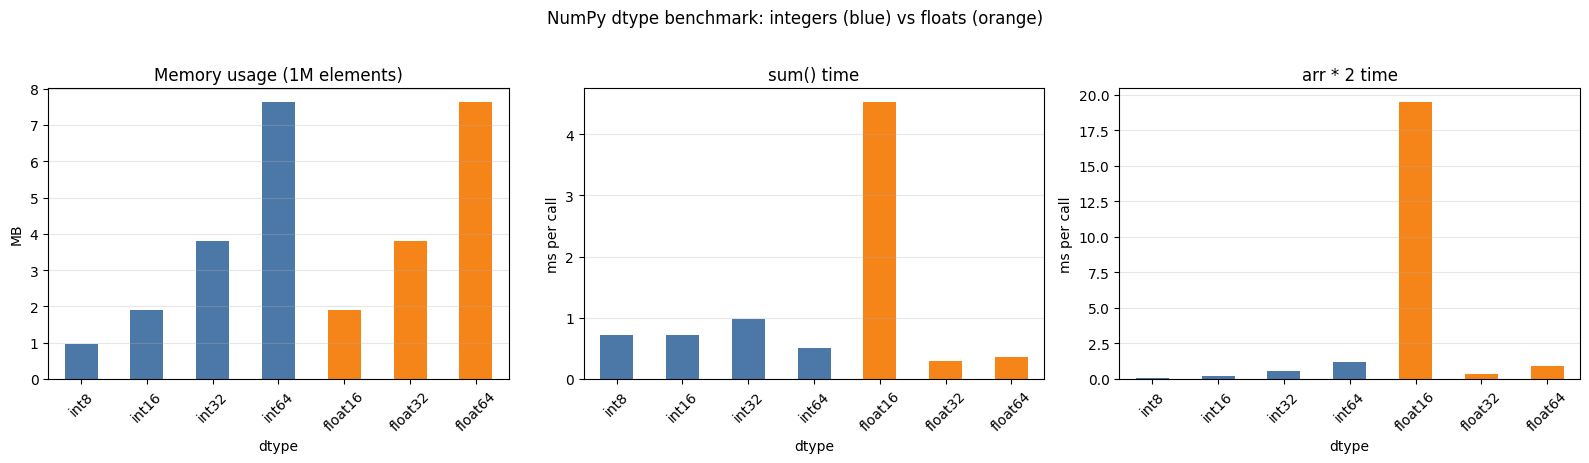

,memory (MB),sum (ms),multiply (ms)
dtype,,,
int8,0.954,0.7112,0.0890
int16,1.907,0.7166,0.1817
int32,3.815,0.9726,0.5365
int64,7.629,0.5011,1.1698
float16,1.907,4.5250,19.4730
float32,3.815,0.2950,0.3564
float64,7.629,0.3621,0.8827


In [8]:
summary = mem_df[["memory (MB)"]].join(time_df)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
colors = ["#4C78A8"]*4 + ["#F58518"]*3     # ints blue, floats orange

summary["memory (MB)"].plot(kind="bar", ax=axes[0], color=colors)
axes[0].set_title("Memory usage (1M elements)")
axes[0].set_ylabel("MB")

summary["sum (ms)"].plot(kind="bar", ax=axes[1], color=colors)
axes[1].set_title("sum() time")
axes[1].set_ylabel("ms per call")

summary["multiply (ms)"].plot(kind="bar", ax=axes[2], color=colors)
axes[2].set_title("arr * 2 time")
axes[2].set_ylabel("ms per call")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("NumPy dtype benchmark: integers (blue) vs floats (orange)", y=1.02)
plt.tight_layout()
plt.savefig("dtype_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()

summary

## Recommendations: how to choose a dtype

*(Read these against your own charts. Exact timings depend on the Colab machine, so update any statement your results do not support.)*

| Situation | Suggested dtype | Why |
|---|---|---|
| Small whole numbers (ages, ratings, 0-255 pixels) | `int8` / `uint8` / `int16` | Up to 8x less memory than int64; check the value range first with `np.iinfo` |
| General counts, IDs, indices | `int32` or `int64` | Safe range, no overflow surprises |
| Machine learning, images, large arrays | `float32` | Half the memory of float64 with enough precision for most work |
| Scientific computing, finance, accumulating many sums | `float64` | Best precision; NumPy default |
| `float16` | Storage only, with care | Tiny range (max 65504) and low precision; overflowed to `inf` in our sum test and was the slowest dtype on CPU |

**Key takeaways**
1. Memory scales directly with itemsize: int8 uses 1/8 of the memory of int64.
2. Smaller dtypes are not always faster for every operation. Check the timing charts above for your machine.
3. Integer overflow wraps silently, and float16 can overflow to `inf`, so verify the value range before downcasting.
4. Choose the **smallest dtype that safely holds your data and precision needs**.